# 23 Vergleichsgruppen und Nachbarn im Leitungsnetz

Teil 5: Anomalien und Monitoring

**Worum es geht**
- Zwei Ergänzungen zum Netzvergleich aus Notebook 19.
- Frage 1: Fallen andere Stationen auf, wenn man jede Station nur mit Häusern vergleicht, die im selben Winter ähnlich viel Wärme abgenommen haben?
- Frage 2: Haben Nachbarn einer auffälligen Station im Leitungsnetz ähnliche Probleme? Das wäre ein Hinweis auf eine Ursache im Netz, etwa zu wenig Vorlauf oder Differenzdruck im Strang.
- Reine Analyse, das Stationsblatt bleibt unverändert.

**Daten**
- liest: bereinigte Stundenreihen, Begehungsbefunde, Leitungsgraph aus `Nodes_Edges.ods`
- schreibt: nichts
- vorher ausführen: Notebook 00

**Code**
- Logik in `src/vergleichsgruppen.py` und `src/nachbarschaft.py`, Tests in `tests/test_vergleichsgruppen.py` und `tests/test_nachbarschaft.py`

In [1]:
import os as _os
from pathlib import Path as _Path
#Arbeitsordner ist immer notebooks/, auch aus den Teil-Ordnern
_os.chdir(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "src").is_dir()) / "notebooks")
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import alarmbewertung as ab
from src import befundcodes as bc
from src import build_graph as bg
from src import fallsammlung as fs
from src import nachbarschaft as ns
from src import netzvergleich as nv
from src import stationsblatt as bl
from src import vergleichsgruppen as vg

warnings.filterwarnings("ignore", category=UserWarning, module="openpyxl")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

t0 = time.time()
e = bl.eingaben(ROOT)
erg = bl.rechne(e["serien"], e["termine"], e["anschlusswerte"], e["bhkw"],
                e["ohne_datum"], baujahr=e["baujahr"])
netz = erg["markiert"]
kz = erg["kennzahlen"]
kodiert = bc.kodiere_begehungen()
kat = {"mechanisch": list(fs.MECHANISCH), "ventil": ["ventil_stellantrieb"]}
print(f"{len(e['serien'])} Stundenreihen aus NB 00, gerechnet in "
      f"{time.time() - t0:.0f} s")
print("Kennzahlen im Score:", ", ".join(kz))

93 Stundenreihen aus NB 00, gerechnet in 22 s
Kennzahlen im Score: spreizung_ref_k, steigung, residuum_sd, rl_ueber_50_anteil, flow_spez_lh_kw


## 1 Vergleichsgruppe nach Wärmemenge

- Wärmemenge im Kernwinter = mittlere Leistung der Betriebsstunden mal Zahl der Stunden im Kernwinter. So zählen Lücken nicht als geringer Verbrauch.
- Das ist nur ein Größenmaß zum Gruppieren, keine Wärmebilanz.

In [2]:
energie = vg.winterenergie(erg["punkte"])
display((energie.groupby("winter")["waermemenge_kwh"]
         .describe()[["count", "min", "50%", "max"]] / [1, 1e3, 1e3, 1e3])
        .rename(columns={"count": "stationen", "min": "min MWh",
                         "50%": "median MWh", "max": "max MWh"}).round(1))

,stationen,min MWh,median MWh,max MWh
winter,,,,
22/23,41.0,3.2,8.5,287.5
23/24,86.0,3.3,9.6,287.0
24/25,84.0,3.2,10.6,300.0
25/26,4.0,3.8,7.7,13.9


- Die Stationen unterscheiden sich um zwei Größenordnungen. Die meisten liegen bei 7 bis 14 MWh je Kernwinter.
- Nächste Frage: Hängt der Netzscore am Verbrauch? Dann wäre der Vergleich mit allen Stationen unfair.

,winter,stationen,rho,p
0,22/23,41,0.322,0.040
1,23/24,86,0.110,0.315
2,24/25,84,0.147,0.184


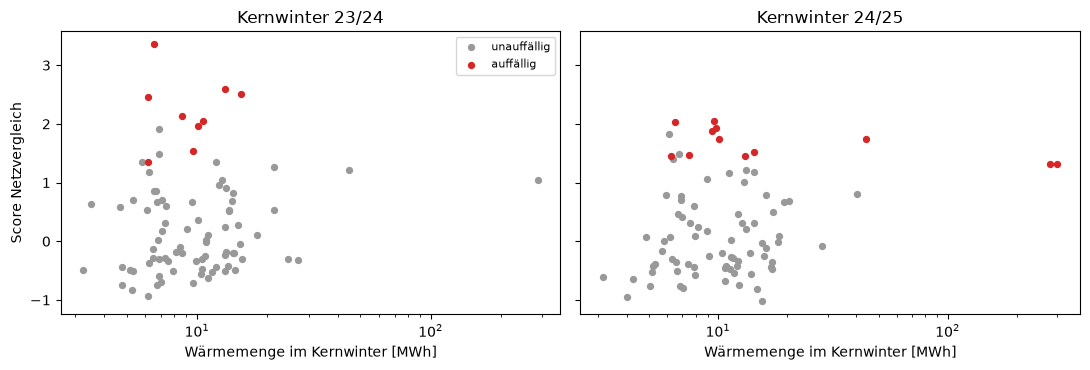

In [3]:
m = netz.merge(energie, on=["meter", "winter"])
m = m[m["score"].notna()]
zeilen = []
for w, g in m.groupby("winter"):
    if len(g) < nv.MIN_STATIONEN_WINTER:
        continue
    rho, p = stats.spearmanr(g["score"], g["waermemenge_kwh"])
    zeilen.append({"winter": w, "stationen": len(g), "rho": rho, "p": p})
display(pd.DataFrame(zeilen).round(3))

winter = [w for w in ("23/24", "24/25") if w in set(m["winter"])]
fig, ax = plt.subplots(1, len(winter), figsize=(11, 3.8), sharey=True)
for a, w in zip(np.atleast_1d(ax), winter):
    g = m[m["winter"] == w]
    for flag, farbe, name in ((False, "0.6", "unauffällig"),
                              (True, "C3", "auffällig")):
        t = g[g["auffaellig"] == flag]
        a.scatter(t["waermemenge_kwh"] / 1e3, t["score"], s=18, c=farbe,
                  label=name)
    a.set_xscale("log")
    a.set_title(f"Kernwinter {w}")
    a.set_xlabel("Wärmemenge im Kernwinter [MWh]")
np.atleast_1d(ax)[0].set_ylabel("Score Netzvergleich")
np.atleast_1d(ax)[0].legend(fontsize=8)
fig.tight_layout()

- Der Zusammenhang ist schwach positiv: Größere Stationen schneiden eher etwas schlechter ab. Signifikant ist das nur im kleinen Winter 22/23.
- Die Kennzahlen sind auf die Leistung bezogen und damit schon größenunabhängig gebaut.
- Vergleichsgruppe: je Station die k Stationen mit der ähnlichsten Wärmemenge im selben Winter (ohne BHKW). Die z-Werte werden gegen diese Gruppe statt gegen das ganze Netz gerechnet.
- "Auffällig" wie bisher. Geprüft für k = 10, 15 und 25.

In [4]:
gruppen = {}
for k in vg.K_SENSITIVITAET:
    gruppen[k] = nv.markiere(vg.gruppenbezug(erg["tabelle"], energie, k=k,
                                             kennzahlen=kz), kz)
    g = gruppen[k]
    print(f"k = {k}: Bezug {g['bezug'].value_counts().to_dict()}, "
          f"Gruppe spannt im Median Faktor "
          f"{g.loc[g['bezug'] == 'gruppe', 'gruppe_faktor'].median():.2f} "
          f"in der Wärmemenge")
vergleich = pd.concat([vg.vergleiche(netz, g).assign(k=k)
                       for k, g in gruppen.items()], ignore_index=True)
vergleich = vergleich[vergleich["n"] > 0]
display(vergleich[["k", "winter", "n", "auffaellig_netz", "auffaellig_gruppe",
                   "beide", "jaccard", "spearman", "neu", "weg"]].round(2))

k = 10: Bezug {'gruppe': 211, 'zu_klein': 4}, Gruppe spannt im Median Faktor 1.19 in der Wärmemenge
k = 15: Bezug {'gruppe': 211, 'zu_klein': 4}, Gruppe spannt im Median Faktor 1.30 in der Wärmemenge


k = 25: Bezug {'gruppe': 211, 'zu_klein': 4}, Gruppe spannt im Median Faktor 1.56 in der Wärmemenge


,k,winter,n,auffaellig_netz,auffaellig_gruppe,beide,jaccard,spearman,neu,weg
0,10,22/23,41,6,6,5,0.71,0.89,[72135440],[72167783]
1,10,23/24,86,9,10,7,0.58,0.90,"[66761022, 72135442, 80912202]","[68956360, 68956372]"
2,10,24/25,84,12,13,9,0.56,0.93,"[68956344, 72135440, 72167777, 80912184]","[68956360, 68956373, 72135442]"
4,15,22/23,41,6,5,4,0.57,0.97,[72135440],"[72135453, 72167783]"
5,15,23/24,86,9,10,7,0.58,0.93,"[66761022, 69513891, 80912202]","[68956360, 72167793]"
6,15,24/25,84,12,12,7,0.41,0.94,"[68956344, 72135440, 80912184, 80912199, 80912...","[68956359, 68956360, 68956373, 80912173, 80912..."
8,25,22/23,41,6,6,5,0.71,0.98,[68956344],[72135453]
9,25,23/24,86,9,10,8,0.73,0.96,"[66761022, 80912202]",[68956360]
10,25,24/25,84,12,12,9,0.60,0.98,"[68956344, 72135440, 72167782]","[68956360, 68956373, 81062289]"


- Die Rangfolge bleibt fast gleich: Rangkorrelation in allen Wintern über 0,9. Auch die Zahl der auffälligen Stationen ändert sich kaum.
- Es wechseln nur Grenzfälle. Bei k = 15 kommen je Winter eine bis fünf Stationen neu dazu, zwei bis fünf fallen weg (Jaccard 0,41 bis 0,58; Jaccard = Anteil der gemeinsamen an allen markierten Stationen). Bei k = 25 sind es nur ein bis drei Wechsel.
- Die Gruppen sind eng: Bei k = 15 liegt zwischen größter und kleinster Station im Median der Faktor 1,3.
- Darunter die Prüfung wie in Notebook 21 an der ersten Begehung nach dem Winter.

In [5]:
varianten = {"Netz": netz, **{f"Gruppe k = {k}": g for k, g in gruppen.items()}}
zeilen = {}
for name, t in varianten.items():
    val = ab.befund_nach_winter(t[t["score"].notna()]
                                [["meter", "winter", "auffaellig"]],
                                kodiert, kat)
    for befund in kat:
        zeilen[f"{name} -> {befund}"] = ab.vierfeld(val["auffaellig"],
                                                    val[befund])
display(pd.DataFrame(zeilen).T.round(3))

,n,merkmal_mit_befund,merkmal_ohne_befund,rest_mit_befund,rest_ohne_befund,quote_merkmal,quote_rest,p (einseitig)
Netz -> mechanisch,50.0,2.0,1.0,15.0,32.0,0.667,0.319,0.264
Netz -> ventil,50.0,2.0,1.0,6.0,41.0,0.667,0.128,0.063
Gruppe k = 10 -> mechanisch,50.0,3.0,0.0,14.0,33.0,1.000,0.298,0.035
Gruppe k = 10 -> ventil,50.0,3.0,0.0,5.0,42.0,1.000,0.106,0.003
Gruppe k = 15 -> mechanisch,50.0,2.0,1.0,15.0,32.0,0.667,0.319,0.264
Gruppe k = 15 -> ventil,50.0,2.0,1.0,6.0,41.0,0.667,0.128,0.063
Gruppe k = 25 -> mechanisch,50.0,2.0,1.0,15.0,32.0,0.667,0.319,0.264
Gruppe k = 25 -> ventil,50.0,2.0,1.0,6.0,41.0,0.667,0.128,0.063


- Bei k = 10 fällt ein auffälliger Stationswinter ohne Ventilbefund heraus, alle drei verbleibenden haben einen Ventilbefund. p sinkt dadurch von 0,063 auf 0,003. Bei k = 15 und 25 bleibt es beim Netzergebnis. Bei nur drei Fällen hängt das an einer Station.
- Der Netzvergleich bleibt Standard. Die Vergleichsgruppe dient als Sensitivitätsprüfung: Wer in beiden Varianten auffällt, ist sicherer markiert.

In [6]:
g15 = gruppen[15]
beide = (netz[["meter", "winter", "auffaellig"]]
         .merge(g15[["meter", "winter", "auffaellig"]], on=["meter", "winter"],
                suffixes=("_netz", "_gruppe")))
beide = beide[beide["auffaellig_netz"] | beide["auffaellig_gruppe"]]
beide["status"] = np.select(
    [beide["auffaellig_netz"] & beide["auffaellig_gruppe"],
     beide["auffaellig_netz"]],
    ["in beiden", "nur Netz"], "nur Gruppe")
display(pd.crosstab(beide["winter"], beide["status"], margins=True))

status,in beiden,nur Gruppe,nur Netz,All
winter,,,,
22/23,4,1,2,7
23/24,7,3,2,12
24/25,7,5,5,17
All,18,9,9,36


## 2 Nachbarn im Leitungsnetz

- Grundlage ist der logische Leitungsgraph aus `Nodes_Edges.ods`.
- Nachbarn liegen höchstens zwei Kanten auseinander, auch über Knoten ohne Zähler. Zur Prüfung zusätzlich eine und drei Kanten.

In [7]:
import networkx as nx

graph = bg.build_logical_graph()
knoten = ns.meter_knoten(graph)
nachbarn = {k: ns.nachbarn(graph, k) for k in ns.KANTEN_SENSITIVITAET}
print(f"{graph.number_of_nodes()} Knoten, {graph.number_of_edges()} Kanten, "
      f"{nx.number_connected_components(graph)} Teilnetze")
print(f"{len(knoten)} Hausstationen mit Zählernummer im Graph")
display(pd.DataFrame({
    f"bis {k} Kanten": pd.Series({m: len(s) for m, s in nb.items()})
    .describe()[["min", "25%", "50%", "75%", "max"]]
    for k, nb in nachbarn.items()}).T)
ohne = sum(1 for s in nachbarn[2].values() if not s)
print(f"{ohne} Stationen ohne Nachbarn mit Zähler (auch bei 2 Kanten)")

118 Knoten, 110 Kanten, 9 Teilnetze
94 Hausstationen mit Zählernummer im Graph


,min,25%,50%,75%,max
bis 1 Kanten,0.0,1.0,1.0,2.00,4.0
bis 2 Kanten,0.0,2.0,3.0,4.75,7.0
bis 3 Kanten,0.0,4.0,5.0,7.00,13.0


8 Stationen ohne Nachbarn mit Zähler (auch bei 2 Kanten)


- Das Netz ist überwiegend eine Kette. Bei zwei Kanten hat eine Station im Median drei Nachbarn mit Zähler.
- Permutationstest: Die Markierung "auffällig ja/nein" wird 10.000-mal zufällig auf die Stationen verteilt. Gezählt werden Nachbarpaare, bei denen beide auffällig sind.
- Dazu die Rangkorrelation des Scores über alle Nachbarpaare.
- Als Kontrolle dieselbe Rechnung für die Wärmemenge: Ähnlicher Verbrauch (etwa gleich alte Häuser) macht einen ähnlichen Score weniger überraschend.

In [8]:
uebersicht = erg["uebersicht"]
im_graph = set(knoten)
mengen = {w: netz[(netz["winter"] == w) & netz["score"].notna()]
          for w in netz["winter"].unique()}
mengen = {w: t for w, t in mengen.items() if len(t) >= nv.MIN_STATIONEN_WINTER}
zeilen = []
for k, nb in nachbarn.items():
    pr = ns.paare(nb)
    faelle = [(w, dict(zip(t["meter"], t["auffaellig"])),
               dict(zip(t["meter"], t["score"])),
               dict(zip(*energie[energie["winter"] == w]
                        [["meter", "waermemenge_kwh"]].to_numpy().T)))
              for w, t in sorted(mengen.items(),
                                 key=lambda x: nv.winter_ende_jahr(x[0]))]
    faelle.append(("chronisch", dict(zip(uebersicht["meter"],
                                         uebersicht["chronisch"])),
                   dict(zip(uebersicht["meter"], uebersicht["score_median"])),
                   None))
    for w, flags, score, menge in faelle:
        j = ns.join_test(pr, flags, stationen=im_graph)
        s = ns.score_test(pr, score, stationen=im_graph)
        z = {"kanten": k, "winter": w, "stationen": j["n_stationen"],
             "auffaellig": j["n_auffaellig"], "paare": j["paare"],
             "beide auffaellig": j["beobachtet"],
             "zufall erwartet": j["erwartet"], "p Paare": j["p"],
             "rho Score": s["beobachtet"], "p Score": s["p"]}
        if menge:
            wm = ns.score_test(pr, {int(a): np.log(float(b))
                                    for a, b in menge.items()},
                               stationen=im_graph)
            z.update({"rho Wärmemenge": wm["beobachtet"], "p Wärmemenge": wm["p"]})
        zeilen.append(z)
haeufung = pd.DataFrame(zeilen)
display(haeufung.round(3))

,kanten,winter,stationen,auffaellig,paare,beide auffaellig,zufall erwartet,p Paare,rho Score,p Score,rho Wärmemenge,p Wärmemenge
0,1,22/23,38,6,15,0,0.317,1.000,0.527,0.009,0.118,0.244
1,1,23/24,79,9,52,1,0.603,0.466,-0.050,0.592,0.122,0.150
2,1,24/25,76,10,49,1,0.790,0.563,-0.061,0.618,0.099,0.193
3,1,chronisch,81,8,54,1,0.469,0.386,-0.058,0.614,NaN,NaN
4,2,22/23,38,6,35,0,0.746,1.000,0.284,0.029,0.253,0.041
5,2,23/24,79,9,117,1,1.354,0.767,0.013,0.350,0.191,0.016
6,2,24/25,76,10,111,2,1.762,0.525,-0.016,0.474,0.113,0.081
7,2,chronisch,81,8,124,1,1.075,0.682,0.008,0.363,NaN,NaN
8,3,22/23,38,6,53,0,1.135,1.000,0.287,0.011,0.133,0.089
9,3,23/24,79,9,182,2,2.121,0.629,0.087,0.082,0.171,0.011


- Keine Häufung: In keinem Winter und bei keiner Weite gibt es mehr auffällige Paare als zufällig erwartet (p zwischen 0,39 und 1). Unter den acht chronischen Stationen gibt es nur ein benachbartes Paar.
- Die Score-Korrelation zeigt nur in 22/23 etwas (direkte Nachbarn, rho um 0,53), bei nur 38 Stationen und 15 Paaren. In 23/24 und 24/25 ist sie weg. Bei zwölf Tabellenzeilen ist ein p unter 0,05 auch zufällig zu erwarten.
- In 23/24 und 24/25 hängt eher die Wärmemenge zusammen (rho um 0,15), der Score kaum. Kein Hinweis auf eine Ursache im Netz.
- Darunter: die Nachbarn jeder auffälligen und jeder chronischen Station, mit auffälligen Nachbarn und gleichem Fehlerbild.

In [9]:
letzter = max(mengen, key=nv.winter_ende_jahr)
fb = ab.fehlerbild_je_winter(netz, list(kz))
fb_w = fb[fb["winter"] == letzter]
tabelle = ns.nachbartabelle(nachbarn[2], netz[netz["winter"] == letzter],
                            dict(zip(fb_w["meter"], fb_w["fehlerbild"])))
print(f"Kernwinter {letzter}: {len(tabelle)} auffällige Stationen, "
      f"{(~tabelle['im_graph']).sum()} davon nicht im Graph")
display(tabelle)
fb_chron = (fb[fb["auffaellig"]].groupby("meter")["fehlerbild"]
            .agg(lambda s: s.mode().iat[0]))
chron = ns.nachbartabelle(nachbarn[2],
                          uebersicht.rename(columns={"chronisch": "auffaellig"}),
                          fb_chron.to_dict())
print("Chronisch auffällige Stationen (auffällig = Nachbar ebenfalls chronisch):")
display(chron)

Kernwinter 24/25: 12 auffällige Stationen, 2 davon nicht im Graph


,meter,fehlerbild,im_graph,n_nachbarn,n_mit_score,n_auffaellig,n_gleiches_bild,nachbarn
0,68956359,unruhig,True,3.0,3.0,1.0,0.0,"80912156, 80912179, 80912182"
1,68956360,ventil,True,3.0,2.0,0.0,0.0,"68956353, 68956363, 72167782"
2,68956373,durchfluss,True,7.0,7.0,1.0,0.0,"68956361, 69513891, 72135442, 72135490, 721677..."
3,72135442,unruhig,True,7.0,5.0,1.0,0.0,"68956361, 68956373, 69527342, 72135490, 721677..."
4,72135453,durchfluss,True,3.0,3.0,0.0,0.0,"68956356, 68956371, 72135478"
5,72135480,ventil,True,0.0,0.0,0.0,0.0,
6,72167793,ventil,True,4.0,4.0,0.0,0.0,"65273846, 68956344, 72135463, 72135481"
7,80912173,ventil,True,1.0,1.0,0.0,0.0,80912179
8,80912182,ventil,True,6.0,6.0,1.0,0.0,"68956359, 68956369, 80912156, 80912163, 809121..."
9,80956410,durchfluss,True,0.0,0.0,0.0,0.0,


Chronisch auffällige Stationen (auffällig = Nachbar ebenfalls chronisch):


,meter,fehlerbild,im_graph,n_nachbarn,n_mit_score,n_auffaellig,n_gleiches_bild,nachbarn
0,68956351,ventil,True,2,1,0,0,"80912171, 80912184"
1,68956360,ventil,True,3,2,1,1,"68956353, 68956363, 72167782"
2,72135442,unruhig,True,7,5,0,0,"68956361, 68956373, 69527342, 72135490, 721677..."
3,72135453,durchfluss,True,3,3,0,0,"68956356, 68956371, 72135478"
4,72135480,ventil,True,0,0,0,0,
5,72167782,ventil,True,1,1,1,1,68956360
6,72167793,ventil,True,4,4,0,0,"65273846, 68956344, 72135463, 72135481"
7,80912182,ventil,True,6,6,0,0,"68956359, 68956369, 80912156, 80912163, 809121..."


- In 24/25 haben vier auffällige Stationen einen auffälligen Nachbarn, jeweils mit anderem Fehlerbild.
- Einziges chronisches Nachbarpaar: 68956360 und 72167782. Beide sind direkt verbunden und haben überwiegend das Fehlerbild Ventil.
- Zu wenig Vorlauf im Strang müsste sich in der Vorlauftemperatur zeigen. Deshalb darunter der Median des Vorlaufs im Kernwinter im Vergleich zum Netz.

In [10]:
zeilen = []
for meter, s in e["serien"].items():
    if "vl" not in s.columns:
        continue
    t = s[(s["power"] > 0) & s["vl"].notna()]
    w = nv.heizperiode(t.index)
    for winter, g in t.groupby(w):
        if winter and len(g) >= nv.MIN_STUNDEN_WINTER:
            zeilen.append({"meter": meter, "winter": winter,
                           "vorlauf_median_c": float(g["vl"].median())})
vorlauf = pd.DataFrame(zeilen)
vorlauf["perzentil_im_netz"] = vorlauf.groupby("winter")["vorlauf_median_c"].rank(pct=True)
paar = [68956360, 72167782]
umfeld = sorted(set(paar) | set().union(*(nachbarn[2][m] for m in paar)))
sicht = vorlauf[vorlauf["meter"].isin(umfeld)
                & vorlauf["winter"].isin(list(mengen))]
display(sicht.pivot(index="meter", columns="winter",
                    values=["vorlauf_median_c", "perzentil_im_netz"]).round(2))
display(vorlauf[vorlauf["winter"].isin(list(mengen))]
        .groupby("winter")["vorlauf_median_c"].median().round(1)
        .rename("Netzmedian °C").to_frame().T)

vorlauf_median_c             perzentil_im_netz            
winter              22/23 23/24 24/25             22/23 23/24 24/25
meter                                                              
68956353             70.7  68.2  66.1              0.29  0.14  0.11
68956360             72.7  74.8  72.6              0.42  0.74  0.50
72167782             75.6  75.4  73.2              0.88  0.87  0.61

winter,22/23,23/24,24/25
Netzmedian °C,73.4,73.2,72.6


- Beide Stationen bekommen einen Vorlauf von etwa 72 bis 75 °C, im Bereich des Netzmedians oder darüber.
- Kein Versorgungsproblem erkennbar. Eher zwei Stationen, die jede für sich schlecht regeln.

## Zusammenfassung & Bewertung

**Ergebnis**
- Beide Ideen ändern am finalen Modell nichts Grundsätzliches.
- Die Vergleichsgruppe bestätigt den Netzvergleich: Die Rangfolge bleibt, nur Grenzfälle wechseln.
- Im Leitungsnetz häufen sich auffällige Stationen nicht. Das einzige chronische Nachbarpaar hat normalen Vorlauf.

**Belastbar**
- Rangkorrelation zwischen Netzvergleich und Vergleichsgruppe in allen Wintern über 0,9.
- Kein Winter und keine Nachbarschaftsweite mit mehr auffälligen Nachbarpaaren als zufällig. Das passt zu Ursachen an der einzelnen Station, nicht im Strang.

**Schwach**
- Die bessere Validierung bei k = 10 hängt an einem Fall.
- Der Graph ist logisch, nicht hydraulisch: keine Leitungslängen, Durchmesser oder Drücke. Acht Stationen haben keine Nachbarn mit Zähler.

**Offen**
- Ob die Vergleichsgruppe als zweite Sicht ins Stationsblatt kommt.
- Belastbarer wäre ein Test mit dem hydraulischen Netzmodell der ÜZ oder mit Differenzdruckmessungen.